<a href="https://colab.research.google.com/github/cristina-vatanabe/Desafios_tecnicos/blob/main/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Passo 1 — Definir a pergunta de negócio e a coluna de análise

* **Pergunta de negócio** : Os atendimentos duram o mesmo tempo em todos os chamados ou alguns são muito longos? E se são longos, por quê?

* **Coluna de análise**: tempo_atendimento_min

* **Decisão que o resultado apoiaria**: Ajudaria a fazer um roteamento inteligente, como separar os atendimentos ente uma fila rápida e uma fila especializada para que não trave os atendimentos com casos complexos.

## Passo 2 — Preparar o ambiente

### Importações

In [1]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

## Passo 3 — Obter os dados

### Carregar os arquivos CSV

In [2]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "clientes"   # ex.: "livros"
NOME_TABELA_FATO = "chamados"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
clientes -> 10400 linhas
chamados -> 42000 linhas


### Conhecendo a tabela dimensão

In [3]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10400 linhas e 4 colunas (variáveis)


,cliente_id,segmento,canal_preferido,data_cadastro
0,1,pequena_empresa,chat,2019-03-01
1,2,pessoa_fisica,chat,2024-04-22
2,3,pessoa_fisica,telefone,2026-05-04
3,4,pequena_empresa,telefone,2025-06-09
4,5,pessoa_fisica,email,2025-06-28


### Conhecendo a tabela fato

In [4]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 42000 linhas e 8 colunas (variáveis)


,chamado_id,cliente_id,data_hora_abertura,canal,motivo,tempo_atendimento_min,nota_satisfacao,resolvido_primeiro_contato
0,1,1180,2026-05-08 06:25:57,chat,solicitacao_tecnica,17,2,False
1,2,5899,2026-05-21 11:21:58,telefone,duvida,21,2,False
2,3,195,2025-03-16 18:37:14,telefone,reclamacao,43,3,False
3,4,3216,2025-04-09 02:17:26,presencial,solicitacao_tecnica,13,5,True
4,5,5598,2026-07-05 18:46:00,chat,elogio,15,3,True


## Passo 4 — Checar a base antes de calcular

### Tipos das colunas

In [5]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   chamado_id                  42000 non-null  int64 
 1   cliente_id                  42000 non-null  int64 
 2   data_hora_abertura          42000 non-null  object
 3   canal                       42000 non-null  object
 4   motivo                      42000 non-null  object
 5   tempo_atendimento_min       42000 non-null  int64 
 6   nota_satisfacao             42000 non-null  int64 
 7   resolvido_primeiro_contato  42000 non-null  bool  
dtypes: bool(1), int64(4), object(3)
memory usage: 2.3+ MB


In [6]:
# Conversão da coluna "data_hora_abertura" que vem classificada como "object"
df_fato["data_hora_abertura"] = pd.to_datetime(df_fato["data_hora_abertura"])

In [7]:
# Validação para ver se a conversão foi relaizada para o tipodata:
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   chamado_id                  42000 non-null  int64         
 1   cliente_id                  42000 non-null  int64         
 2   data_hora_abertura          42000 non-null  datetime64[ns]
 3   canal                       42000 non-null  object        
 4   motivo                      42000 non-null  object        
 5   tempo_atendimento_min       42000 non-null  int64         
 6   nota_satisfacao             42000 non-null  int64         
 7   resolvido_primeiro_contato  42000 non-null  bool          
dtypes: bool(1), datetime64[ns](1), int64(4), object(2)
memory usage: 2.3+ MB


### Valores ausentes

In [8]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
chamado_id                    0
cliente_id                    0
data_hora_abertura            0
canal                         0
motivo                        0
tempo_atendimento_min         0
nota_satisfacao               0
resolvido_primeiro_contato    0
dtype: int64


### Linhas duplicadas

In [9]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


### Chave estrangeira

In [10]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "cliente_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "cliente_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

**Leitura da conferência**

Verificou-se que a tabela fato possui 42.000 linhas e 8 colunas (df_fato.shape) e apresenta 0 linhas duplicadas (df_fato.duplicated().sum()), garantindo a unicidade dos registros de atendimento. A integridade referencial também foi confirmada, pois todos os valores da chave estrangeira (cliente_id) na tabela fato correspondem a identificadores válidos na tabela dimensão (Chaves estrangeiras que batem: True). Além disso, a variável principal de análise (tempo_atendimento_min) não possui valores ausentes, assim como todas as demais colunas da base, que contam com 42.000 registros preenchidos (0 nulos), dispensando tratamentos de imputação ou descarte por erro de preenchimento antes do cálculo das métricas.

## Passo 5 — Medidas de tendência central e dispersão

### Checar a coluna numérica

In [11]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_atendimento_min"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 42000 | ausentes: 0


### Medidas estatísticas

In [12]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,15.60
Mediana,13.00
Moda,9.00
Desvio padrão,11.28
Variância,127.24
Mínimo,1.00
Máximo,107.00
Amplitude,106.00


Média - mediana: 2.6


## Passo 6 — Escrever as frases de insight

```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

- **A média de "tempo_atendimento_min" é 15,60 minutos**. Indica o tempo médio que os funcionários estão levando para atender os clientes independemente do canal.

- **A mediana de "tempo_atendimento_min" é 13,00 minutos**. A mediana indica que 50% dos atendimentos são resolvidos em até 13 minutos. A média é maior que a mediana indicando uma assimetria positiva (cauda longa à direita). Isso confirma que a maioria dos chamados é resolvida de forma rápida, mas existem alguns atendimentos que são extremamente longos, puxando a média para cima.

- **O desvio padrão de "tempo_atendimento_min" é 11,28**. O desvio padrão junto com o valor da amplitude(106 minutos) demonstram uma alta variabilidade e baixa padronização no tempo de atendimento.

- **Decisão final:** Como a alta dispersão dos tempos (desvio padrão de 11,28 min) e os chamados extremos distorcem a média para 15,60 minutos em relação à mediana de 13,00 minutos, a operação deve abandonar o dimensionamento e as metas baseadas na média única, segmentando os atendimentos em filas de triagem por complexidade (N1 para resolução rápida e N2 para casos longos).

## Passo 7 — Ampliar a análise: comparar grupos

### Juntar a fato com a dimensão

In [13]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 42000 | depois da junção: 42000


In [14]:
df_completo.head()

,chamado_id,cliente_id,data_hora_abertura,canal,motivo,tempo_atendimento_min,nota_satisfacao,resolvido_primeiro_contato,segmento,canal_preferido,data_cadastro
0,1,1180,2026-05-08 06:25:57,chat,solicitacao_tecnica,17,2,False,pessoa_fisica,email,2024-12-30
1,2,5899,2026-05-21 11:21:58,telefone,duvida,21,2,False,grande_empresa,chat,2022-09-12
2,3,195,2025-03-16 18:37:14,telefone,reclamacao,43,3,False,pessoa_fisica,email,2021-11-22
3,4,3216,2025-04-09 02:17:26,presencial,solicitacao_tecnica,13,5,True,pessoa_fisica,email,2022-03-10
4,5,5598,2026-07-05 18:46:00,chat,elogio,15,3,True,pessoa_fisica,telefone,2020-10-03


### Comparar grupos por uma coluna da fato

In [15]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "resolvido_primeiro_contato"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
resolvido_primeiro_contato,,,,
False,19684,23.46,22.0,11.59
True,22316,8.67,9.0,4.28


```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

**Leitura por resolvido_primeiro_contato**

Ao segmentar os 42.000 atendimentos pela resolução no primeiro contato (resolvido_primeiro_contato), observa-se que o grupo False (chamados não resolvidos de imediato, com 19.684 registros) apresenta a maior média de duração, atingindo 23,46 minutos contra 8,67 minutos do grupo True (22.316 registros). A mediana confirma integralmente essa diferença expressiva, saltando de 9,0 minutos nos casos resolvidos de primeira para 22,0 minutos nos não resolvidos. Além de serem quase três vezes mais demorados, os atendimentos do grupo False concentram o maior desvio padrão (11,59 minutos, frente a 4,28 minutos no grupo True), indicando que os tempos desse segmento são muito mais espalhados e imprevisíveis. Como os dois grupos possuem médias e medianas completamente distantes entre si, conclui-se que a resolução no primeiro contato é um fator determinante (forte diferenciador) para explicar o tempo de atendimento: quando o agente não consegue solucionar a demanda na primeira interação, o processo se alonga e gera os principais gargalos e outliers da operação.

In [16]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "motivo"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
motivo,,,,
elogio,2120,15.85,13.0,11.33
solicitacao_tecnica,10389,15.69,13.0,11.42
reclamacao,10511,15.65,13.0,11.35
duvida,14736,15.54,13.0,11.25
cancelamento,4244,15.37,13.0,10.85


```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

Ao analisar o tempo de atendimento agrupado pelo motivo do contato (motivo), observa-se que o grupo elogio apresenta numericamente a maior média (15,85 minutos), seguido por solicitacao_tecnica (15,69 min), reclamacao (15,65 min), duvida (15,54 min) e cancelamento (15,37 min). No entanto, a mediana não confirma essa diferença, mantendo-se idêntica em 13,0 minutos para todas as cinco categorias. Quanto à dispersão, o grupo solicitacao_tecnica registra o maior desvio padrão (11,42 minutos), embora os valores estejam muito próximos entre todos os motivos (variando entre 10,85 e 11,42 minutos). Em relação ao volume da amostra (count), o grupo elogio possui a menor quantidade de registros (2.120 contra 14.736 de dúvida e 10.511 de reclamação), o que pede cautela para não supervalorizar pequenas variações na média desse grupo específico, apesar de todas as categorias possuírem amostras robustas. Como os grupos apresentam médias muito próximas (diferença máxima de apenas 0,48 minuto) e medianas exatamente iguais, conclui-se que o motivo do contato não explica a variação no tempo de atendimento, reforçando que a real causa dos chamados longos está na falta de resolução no primeiro contato (resolvido_primeiro_contato = False), e não na natureza inicial da demanda.

In [17]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "canal"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
canal,,,,
telefone,12615,15.70,13.0,11.38
presencial,4131,15.65,13.0,11.19
chat,14762,15.63,13.0,11.32
email,10492,15.42,13.0,11.14


```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

Ao analisar o tempo de atendimento agrupado pelo canal efetivo do chamado (canal), observa-se que o grupo telefone apresenta numericamente a maior média (15,70 minutos), seguido por presencial (15,65 min), chat (15,63 min) e email (15,42 min). No entanto, a mediana não confirma essa diferença, mantendo-se idêntica em 13,0 minutos para todas as quatro categorias. Quanto à dispersão, o grupo telefone registra o maior desvio padrão (11,38 minutos), mas os valores permanecem praticamente uniformes entre os canais (variando apenas entre 11,14 e 11,38 minutos). Em relação ao volume da amostra (count), embora o atendimento presencial possua a menor quantidade de registros (4.131 contra 14.762 do chat), todas as categorias contam com amostras robustas e representativas. Como os grupos apresentam médias muito próximas (diferença máxima de apenas 0,28 minuto) e medianas exatamente iguais, conclui-se que o canal utilizado no atendimento não explica a variação na duração dos chamados, descartando o meio de contato como causa raiz dos atendimentos longos.

### Comparar grupos por uma coluna da dimensão

In [18]:
COLUNA_GRUPO = "canal_preferido"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
canal_preferido,,,,
email,10614,15.70,13.0,11.51
chat,14842,15.59,13.0,11.16
presencial,4123,15.58,13.0,11.25
telefone,12421,15.54,13.0,11.23


```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

Ao analisar o tempo de atendimento agrupado pelo canal preferido do cliente (canal_preferido), observa-se que o grupo email apresenta numericamente a maior média (15,70 minutos), seguido por chat (15,59 min), presencial (15,58 min) e telefone (15,54 min). No entanto, a mediana não confirma essa diferença, mantendo-se idêntica em 13,0 minutos para todas as quatro categorias. Da mesma forma, o grupo email registra o maior desvio padrão (11,51 minutos), mas a dispersão dos valores é praticamente uniforme entre todos os canais (variando apenas entre 11,16 e 11,51 minutos). Quanto ao volume da amostra (count), embora o canal presencial possua a menor quantidade de registros (4.123 contra 14.842 do chat), todas as categorias contam com amostras robustas e representativas. Como os grupos apresentam médias quase idênticas (diferença máxima de apenas 0,16 minuto) e medianas exatamente iguais, conclui-se que o canal preferido do cliente não explica a variação no tempo de atendimento, devendo ser descartado como fator causador dos chamados longos.

In [19]:
COLUNA_GRUPO = "segmento"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
segmento,,,,
grande_empresa,2066,15.70,13.0,11.56
pessoa_fisica,31534,15.62,13.0,11.29
pequena_empresa,8400,15.53,13.0,11.18


```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

Ao analisar o tempo de atendimento agrupado pelo segmento do cliente (segmento), observa-se que o grupo grande_empresa apresenta numericamente a maior média (15,70 minutos), seguido por pessoa_fisica (15,62 min) e pequena_empresa (15,53 min). No entanto, a mediana não confirma essa diferença, mantendo-se idêntica em 13,0 minutos para todas as três categorias. Da mesma forma, o grupo grande_empresa registra o maior desvio padrão (11,56 minutos), mas a dispersão dos valores é praticamente uniforme entre os segmentos (variando apenas entre 11,18 e 11,56 minutos). Quanto ao volume da amostra (count), o grupo grande_empresa possui a menor quantidade de registros (2.066 contra 31.534 de pessoa física e 8.400 de pequena empresa), o que exige maior cautela ao interpretar pequenas oscilações nesse grupo, embora todas as categorias tenham amostras expressivas. Como os grupos apresentam médias quase idênticas (diferença máxima de apenas 0,17 minuto) e medianas exatamente iguais, conclui-se que o segmento do cliente não explica a variação no tempo de atendimento, devendo também ser descartado como causa raiz dos chamados longos.

## Passo 8 — Tratar valores ausentes e outliers, e registrar a decisão

### Regra do IQR

In [20]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -14.00 a 42.00
Outliers: 1247 de 42000 valores
Maiores valores: [107, 96, 96, 95, 93]
Menores valores: [1, 1, 1, 1, 1]


### Medidas com e sem os candidatos a outlier

In [21]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,15.60,14.50
Mediana,13.00,13.00
Desvio padrão,11.28,9.38


```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

**Leitura e decisão registrada**

Na análise de valores extremos pela regra do intervalo interquartil (IQR), foram identificados 1.247 candidatos a outliers dentre os 42.000 registros, correspondendo aos atendimentos que ultrapassam o limite superior de 42,00 minutos (chegando ao máximo de 107 minutos), uma vez que o limite inferior calculado foi negativo (-14,00) e o menor valor real registrado é 1 minuto. Ao remover temporariamente esses 1.247 registros para comparação, a média cai de 15,60 para 14,50 minutos e o desvio padrão reduz de 11,28 para 9,38 minutos, enquanto a mediana permanece inalterada em 13,00 minutos, comprovando sua robustez frente às distorções da cauda longa.
* Decisão: Manter os registros na base de dados. Esses chamados longos (entre 43 e 107 minutos) não representam erros de digitação ou falhas de coleta, mas sim fenômenos reais e legítimos da operação — como demandas complexas que não foram resolvidas no primeiro contato — e constituem exatamente o objeto central da pergunta de negócio para dimensionamento e melhoria de processo.   
* Valores ausentes: Nenhum tratamento foi necessário, pois a coluna analisada (tempo_atendimento_min) possui todos os 42.000 valores preenchidos e 0 registros ausentes, mantendo a integridade completa da amostra original.

## Passo 9 — Ler a distribuição dos valores

### Assimetria (skew)

In [22]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 1.39


### Percentis

In [23]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     4.0
0.25     7.0
0.50    13.0
0.75    21.0
0.90    31.0
Name: tempo_atendimento_min, dtype: float64


### Quantidade de valores por faixa

In [24]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_atendimento_min,
"(0.894, 22.2]",32710
"(22.2, 43.4]",8169
"(43.4, 64.6]",1018
"(64.6, 85.8]",92
"(85.8, 107.0]",11


```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

**Leitura da distribuição**

A análise da forma dos dados apresenta uma assimetria (skew) de 1,39, valor positivo que indica uma cauda longa estendida para valores altos (à direita), demonstrando que os atendimentos se concentram nos tempos mais curtos enquanto uma parcela menor se prolonga significativamente. Na leitura dos percentis, verifica-se que 75% dos registros são concluídos em até 21,0 minutos (percentil 0,75) e 90% dos atendimentos levam até 31,0 minutos (percentil 0,90). Na divisão da variável em 5 faixas de mesmo tamanho, a primeira faixa (de 0,894 a 22,2 minutos) concentra 32.710 registros, ao passo que nas duas faixas mais altas o volume cai para apenas 103 registros no total (sendo 92 na faixa de 64,6 a 85,8 minutos e 11 na faixa de 85,8 a 107,0 minutos)

## Passo 10 — Redigir a recomendação de decisão

```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

## Recomendação

* **Pergunta de negócio**: Os atendimentos duram o mesmo tempo em todos os chamados ou alguns são muito longos? E se são longos, por quê?

* **Evidência 1**: Na base geral, a média é de 15,60 minutos e a mediana é de 13,00 minutos (diferença de 2,6 minutos), acompanhadas por um desvio padrão de 11,28 minutos, assimetria de 1,39 e P90 de 31,0 minutos (com máximo de 107,00 minutos). Isso significa que os tempos não são uniformes: enquanto a maioria dos atendimentos é resolvida rapidamente (metade em até 13 minutos), existe uma cauda longa de chamados muito demorados e altamente dispersos que puxam a média para cima.   

* **Evidência 2**: Ao segmentar pela resolução no primeiro contato (resolvido_primeiro_contato), os chamados não resolvidos de imediato (False) apresentam média de 23,46 minutos, mediana de 22,0 minutos e desvio padrão de 11,59 minutos, contra média de 8,67 minutos, mediana de 9,0 minutos e desvio padrão de 4,28 minutos nos resolvidos de primeira (True). Já nas demais categorias analisadas (motivo, canal, canal_preferido e segmento), as medianas permanecem idênticas em 13,0 minutos e as médias variam minimamente (entre 15,37 e 15,85 minutos). Isso comprova que o fator determinante para os atendimentos longos e imprevisíveis é a falta de resolução na primeira interação, e não o motivo, o canal ou o perfil do cliente.   

* **Recomendação em uma frase**: A operação deve criar uma fila especializada (Nível 2) e capacitar a equipe para aumentar a resolução no primeiro contato, evitando que chamados complexos travem o atendimento rápido das demandas simples.   

* **Limites da análise**: Esta análise foi conduzida sobre uma base de dados fictícia construída para fins de estudo, portanto os resultados ilustram comportamentos simulados e não representam uma operação real. Durante o tratamento dos dados, nenhum registro ausente foi encontrado nos 42.000 chamados, e os 1.247 candidatos a outliers identificados pela regra do IQR (acima de 42,00 minutos) foram mantidos na base por representarem atendimentos longos legítimos e essenciais para responder ao problema de negócio.

## Passo 11 — Gráficos simples e legíveis (diferencial)

### Histograma

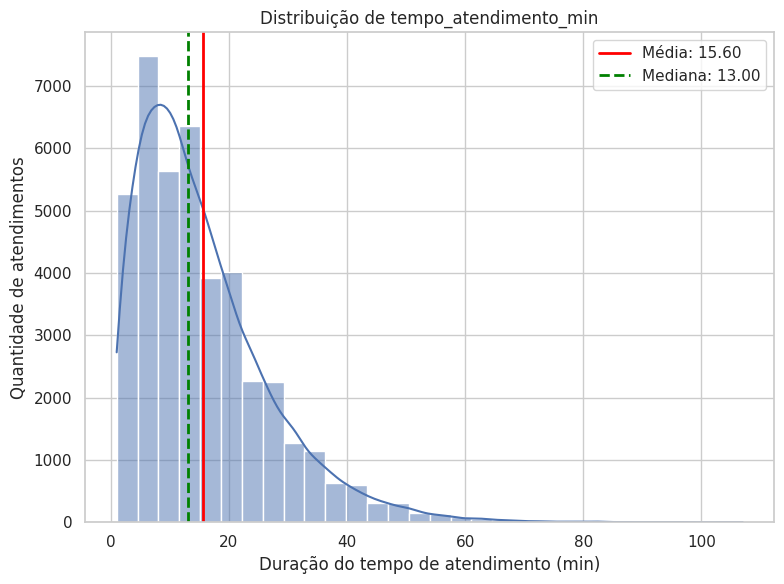

In [25]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Duração do tempo de atendimento (min)")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("Quantidade de atendimentos")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

O histograma mostra uma forte concentração de atendimentos nas faixas mais rápidas (pico próximo a 9 minutos e maioria abaixo de 20 minutos), seguida por uma cauda longa que se estende até além de 100 minutos, ilustrando visualmente uma distribuição assimétrica à direita em que uma minoria de chamados extremamente longos puxa a média (15,60 min, linha vermelha) para cima da mediana (13,00 min, linha verde) e evidencia que a operação não possui um tempo padrão único.

### Boxplot

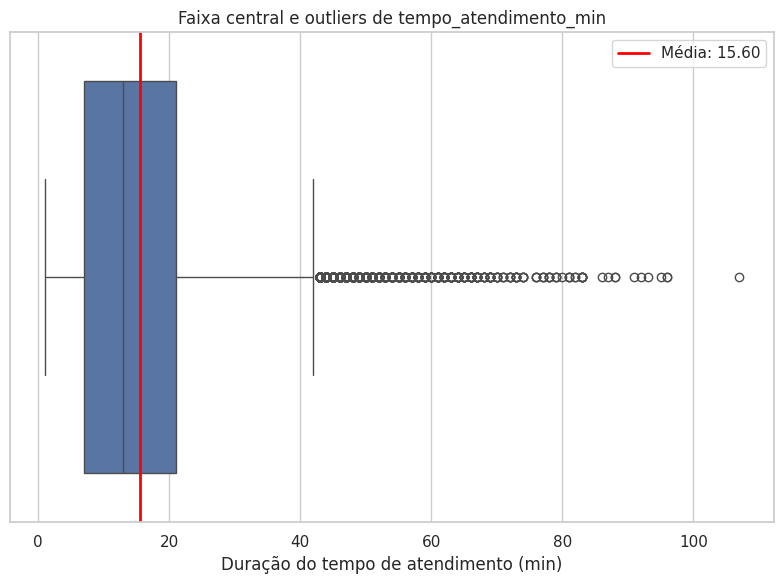

In [26]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Duração do tempo de atendimento (min)")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

O boxplot mostra que a faixa central de 50% dos atendimentos (a caixa azul, entre 7 e 21 minutos) é bastante compacta, mas há uma longa sequência de pontos fora do limite superior (acima de 42 minutos, chegando a 107 minutos), ilustrando visualmente como esses chamados extremos deslocam a linha vermelha da média (15,60 min) para a direita da mediana (13,00 min) e comprovam que a operação sofre com gargalos pontuais de alta duração.

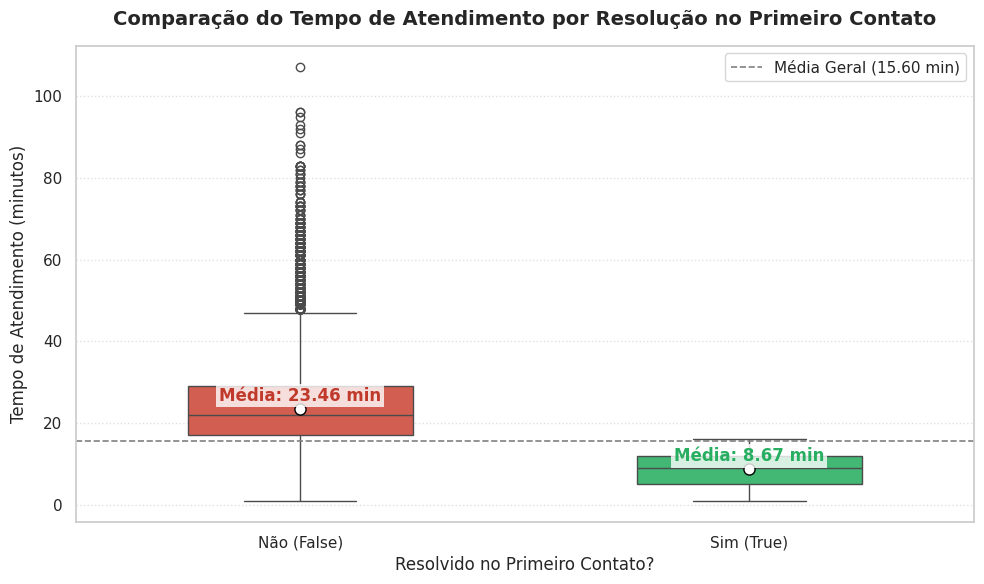

In [29]:
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Gráfico 3: Comparação da duração por resolução no primeiro contato (FCR)
plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    data=df_completo,
    x='resolvido_primeiro_contato',
    y='tempo_atendimento_min',
    palette=['#e74c3c', '#2ecc71'],  # Vermelho para Não resolvido, Verde para Resolvido
    width=0.5,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": "8"
    }
)

# Títulos e rótulos em linguagem de negócio
plt.title('Comparação do Tempo de Atendimento por Resolução no Primeiro Contato', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Resolvido no Primeiro Contato?', fontsize=12)
plt.ylabel('Tempo de Atendimento (minutos)', fontsize=12)
plt.xticks(ticks=[0, 1], labels=['Não (False)', 'Sim (True)'], fontsize=11)

# Destaque das médias diretamente no gráfico
medias = df_completo.groupby('resolvido_primeiro_contato')['tempo_atendimento_min'].mean()

plt.text(0, medias[False] + 2, f'Média: {medias[False]:.2f} min', ha='center', fontweight='bold', color='#c0392b', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2))
plt.text(1, medias[True] + 2, f'Média: {medias[True]:.2f} min', ha='center', fontweight='bold', color='#27ae60', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2))

# Linha de referência da média geral (15,60 min)
media_geral = df_completo['tempo_atendimento_min'].mean()
plt.axhline(media_geral, color='gray', linestyle='--', linewidth=1.2, label=f'Média Geral ({media_geral:.2f} min)')

plt.legend(loc='upper right', frameon=True)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

```text
# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

A comparação visual confirma que a ausência de resolução no primeiro contato (Não) desloca todo o patamar de duração dos chamados para cima, elevando a média para 23,46 min — quase o triplo dos 8,67 min observados nos atendimentos resolvidos de imediato (Sim). A linha tracejada evidencia que a quase totalidade dos chamados resolvidos no primeiro contato permanece abaixo da média geral da operação (15,60 min), reforçando visualmente a recomendação de triagem e roteamento especializado.

## Registrar o uso de IA e entregar

Registro de uso de IA: Utilizei a IA (Gemini) como ferramenta de apoio para estruturar e redigir os textos de interpretação analítica (Passos 4, 7, 8, 9, 10 e 11). Por estar em processo de aprendizagem na área de análise de dados, ainda não me sinto totalmente segura para redigir todas as conclusões técnicas sozinha, mas compreendo que a prática constante é essencial; por isso, seguirei revisando esses conceitos e desenvolvendo novos exercícios e projetos para consolidar o conteúdo e ganhar autonomia na escrita analítica. As marcações de uso foram devidamente inseridas no topo das células correspondentes.